# Proposed Breast Cancer Ontology (BCMO v2.0)
## Ontology-Grounded LLMs for Detecting Breast Cancer Misinformation

**Team:** Meharry Medical College NLP Project (Topic 4)  
**Data Source:** MedQuAD (Medical Question Answering Dataset)  
**Date:** October 2026

---

### Overview

This notebook presents the complete pipeline for building the **Breast Cancer Misinformation Ontology (BCMO)**, a purpose-built ontology for detecting misinformation in breast cancer patient conversations. The ontology combines:

1. **Data-grounded knowledge** extracted from 43 breast-cancer-focused MedQuAD documents across 6 subsets
2. **Expert-curated knowledge** from NCI Thesaurus, UMLS, and NCCN Clinical Practice Guidelines

The pipeline has 4 stages:
1. **Data Extraction** -- Parse MedQuAD XML, filter breast cancer documents, extract concepts
2. **Relation Mining** -- Extract semantic triples from QA text with provenance
3. **Ontology Construction** -- Merge extracted + expert knowledge into BCMO v2
4. **Validation & Visualization** -- Coverage stats, consistency checks, visualizations


## 1. Setup and Imports

In [1]:
import sys, os, json, re
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import defaultdict
from datetime import datetime

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 100
matplotlib.rcParams['figure.figsize'] = (10, 6)

import networkx as nx

# Resolve project root (one level up from notebooks/)
PROJECT_DIR = Path(os.path.abspath('')).parent if Path(os.path.abspath('')).name == 'notebooks' else Path(os.path.abspath(''))
os.chdir(PROJECT_DIR)
DATA_DIR = PROJECT_DIR / "data"
MEDQUAD_DIR = PROJECT_DIR / "MedQuAD"

# Add src to path
sys.path.insert(0, str(PROJECT_DIR / "src" / "data_prep"))
sys.path.insert(0, str(PROJECT_DIR / "src" / "ontology"))

print(f"Project directory: {PROJECT_DIR}")
print(f"MedQuAD directory: {MEDQUAD_DIR}")
print(f"Data directory: {DATA_DIR}")


Project directory: /Users/malinisenthilkumar/Documents/Meharry/nlp
MedQuAD directory: /Users/malinisenthilkumar/Documents/Meharry/nlp/MedQuAD
Data directory: /Users/malinisenthilkumar/Documents/Meharry/nlp/data


> **Output Explanation:** This cell configures the working environment by importing all required libraries (pandas for data tables, matplotlib for charts, networkx for graph visualization) and setting up file paths to the MedQuAD dataset and data output directories. The printed paths confirm the notebook can locate the project files correctly.

---
## 2. Stage 1: MedQuAD Data Extraction

### 2.1 Parse MedQuAD XML Files

We scan all 12 MedQuAD subdirectories and apply strict Focus-tag filtering to select only breast-cancer-relevant documents. This avoids the over-inclusion problem where documents merely mentioning "breast cancer" in passing (e.g., Hodgkin Lymphoma) were previously included.


In [2]:
from parse_medquad import parse_all_medquad, extract_question_types

breast_docs, extracted_concepts = parse_all_medquad()


Breast-cancer-focused documents: 43

Documents by MedQuAD subset:
  10_MPlus_ADAM_QA: 27
  1_CancerGov_QA: 5
  2_GARD_QA: 4
  3_GHR_QA: 1
  4_MPlus_Health_Topics_QA: 5
  7_SeniorHealth_QA: 1

Extracted concept categories:
  biomarker: 9 unique concepts
    - BRCA1
    - BRCA2
    - Estrogen Receptor
    - HER2
    - HER2/neu
    - MammaPrint
    - Oncotype DX
    - Progesterone Receptor
    - TP53
  breast_cancer_subtype: 16 unique concepts
    - Ductal Carcinoma In Situ
    - ER-Positive Breast Cancer
    - HER2-Positive Breast Cancer
    - Hormone Receptor-Negative Breast Cancer
    - Hormone Receptor-Positive Breast Cancer
    - Inflammatory Breast Cancer
    - Invasive Breast Cancer
    - Invasive Ductal Carcinoma
    - Invasive Lobular Carcinoma
    - Lobular Carcinoma In Situ
    - Metaplastic Carcinoma
    - Metastatic Breast Cancer
    - PR-Negative Breast Cancer
    - PR-Positive Breast Cancer
    - Paget Disease of the Nipple
    - Triple-Negative Breast Cancer
  diagnostic_t

> **Output Explanation:** The parser scanned all 12 MedQuAD subdirectories and applied strict Focus-tag filtering to identify **43 breast-cancer-focused documents** across 6 subsets. Unlike the previous v1 approach (which over-included 41 documents by matching any mention of "breast cancer" in QA text), this strict filter ensures only documents whose primary topic is breast cancer are included. The output shows the count per subset and the normalized concepts extracted from QA answer text across 10 categories (subtypes, biomarkers, treatments, diagnostics, symptoms, risk factors, protective factors, genetic factors, stages, and side effects).

### 2.2 Document Distribution by MedQuAD Subset

,MedQuAD Subset,Document Count
0,10_MPlus_ADAM_QA,27
1,1_CancerGov_QA,5
2,2_GARD_QA,4
3,3_GHR_QA,1
4,4_MPlus_Health_Topics_QA,5
5,7_SeniorHealth_QA,1


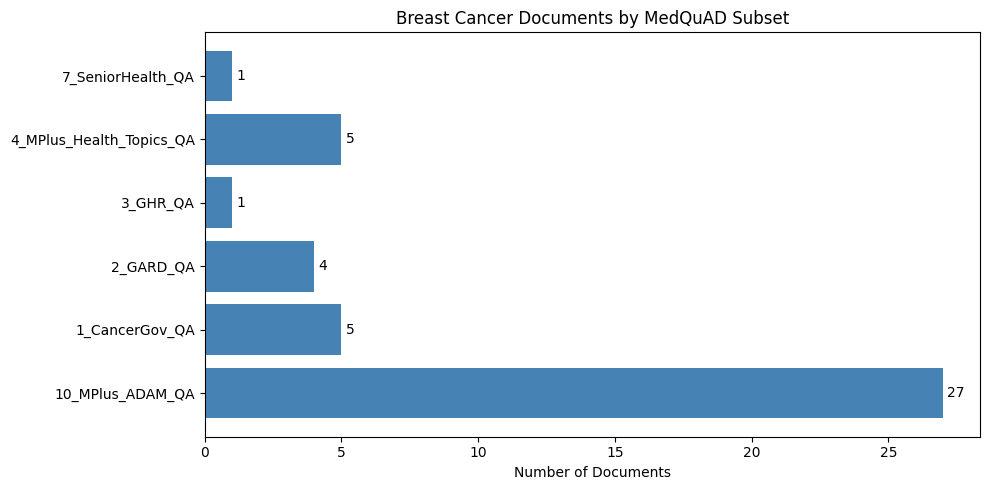


Total breast-cancer-focused documents: 43


In [3]:
# Count documents per subset
subset_counts = defaultdict(int)
for doc in breast_docs:
    subset_counts[doc["subset"]] += 1

df_subsets = pd.DataFrame(
    sorted(subset_counts.items()),
    columns=["MedQuAD Subset", "Document Count"]
)
display(df_subsets)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(df_subsets["MedQuAD Subset"], df_subsets["Document Count"], color='steelblue')
ax.set_xlabel("Number of Documents")
ax.set_title("Breast Cancer Documents by MedQuAD Subset")
ax.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()
print(f"\nTotal breast-cancer-focused documents: {len(breast_docs)}")


> **Output Explanation:** The table and horizontal bar chart show how the 43 breast cancer documents are distributed across MedQuAD subsets. **MedlinePlus ADAM (10_MPlus_ADAM_QA)** contributes the most documents (27), covering topics like breast cancer staging, screening, mastectomy, and hormone therapy. **CancerGov (1_CancerGov_QA)** provides the 5 core comprehensive breast cancer treatment documents. The remaining documents come from MedlinePlus Health Topics, GARD (rare diseases like inflammatory and metaplastic breast cancer), GHR (breast cancer genetics), and SeniorHealth. This multi-subset approach captures a broader range of breast cancer knowledge than using CancerGov alone.

### 2.3 Question Type Distribution

,Question Type,Count
0,information,52
1,treatment,20
2,susceptibility,14
3,symptoms,12
4,outlook,11
5,exams and tests,9
6,when to contact a medical professional,8
7,causes,7
10,research,5
8,prevention,5


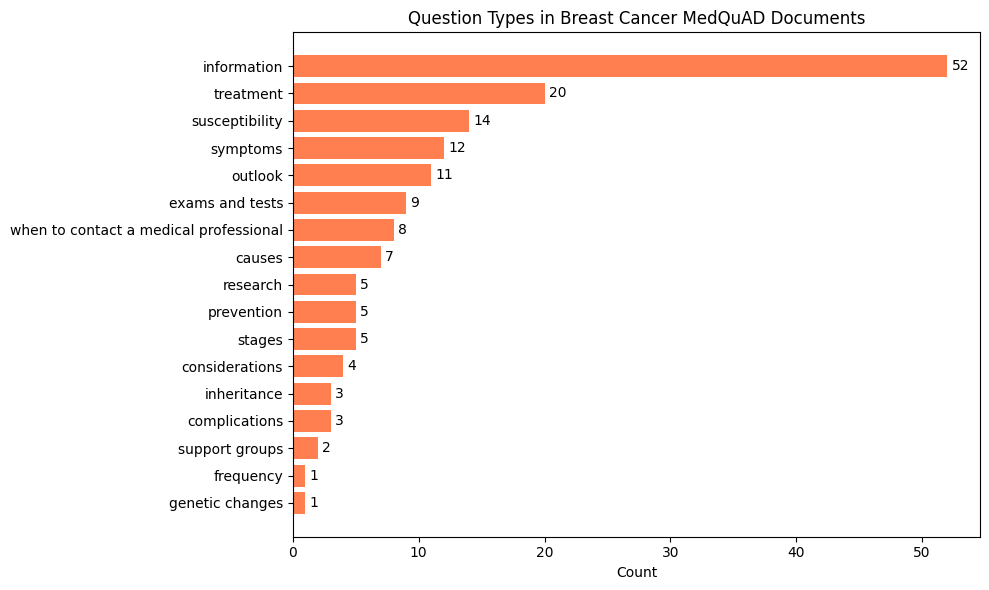

In [4]:
qtypes = extract_question_types(breast_docs)
df_qtypes = pd.DataFrame(
    list(qtypes.items()),
    columns=["Question Type", "Count"]
).sort_values("Count", ascending=False)
display(df_qtypes)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(df_qtypes["Question Type"][::-1], df_qtypes["Count"][::-1], color='coral')
ax.set_xlabel("Count")
ax.set_title("Question Types in Breast Cancer MedQuAD Documents")
ax.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()


> **Output Explanation:** The table and bar chart display the distribution of **17 distinct question types** across the 43 documents, totaling 161 QA pairs. The most common types are: **information** (52 -- general descriptions of the disease), **treatment** (20 -- therapeutic options), **susceptibility** (14 -- risk factors), and **symptoms** (12 -- signs of breast cancer). These question types serve as semantic signals for relation extraction: treatment questions yield `treats` relations, susceptibility questions yield `increases_risk_of` relations, etc. The diversity of question types enables extraction of a comprehensive set of ontology relations.

### 2.4 Extracted Concepts Summary

,Category,Count,Examples
0,biomarker,9,"BRCA1, BRCA2, Estrogen Receptor, HER2"
1,breast_cancer_subtype,16,"Ductal Carcinoma In Situ, ER-Positive Breast C..."
2,diagnostic_test,15,"Biopsy, Blood Chemistry Studies, Bone Scan, CT..."
3,genetic_factor,6,"BRCA1 Gene Mutation, BRCA2 Gene Mutation, Cowd..."
4,protective_factor,3,"Breastfeeding, Early Pregnancy, Physical Exercise"
5,risk_factor,13,"Age, Alcohol Consumption, Dense Breast Tissue,..."
6,side_effect,7,"Blood Clots, Bone Loss, Heart Failure, Hot Fla..."
7,stage,15,"Locally Advanced, Metastatic, Stage 0, Stage 0..."
8,symptom,8,"Breast Lump, Breast Thickening, Lymphedema, Ni..."
9,treatment,26,"Ado-Trastuzumab Emtansine, Anastrozole, Aromat..."


/var/folders/fw/jjvv22050k19sr97kh_2y3br0000gn/T/ipykernel_74819/3311613229.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_concepts["Category"], rotation=45, ha='right')


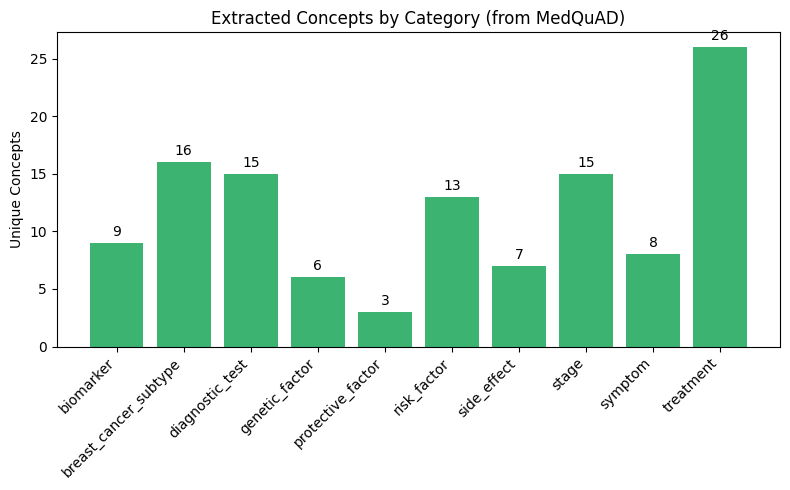


Total unique concepts extracted: 118


In [5]:
# Summary table
concept_summary = []
for cat, items in sorted(extracted_concepts.items()):
    concept_summary.append({"Category": cat, "Count": len(items), "Examples": ", ".join(items[:4])})
df_concepts = pd.DataFrame(concept_summary)
display(df_concepts)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(df_concepts["Category"], df_concepts["Count"], color='mediumseagreen')
ax.set_ylabel("Unique Concepts")
ax.set_title("Extracted Concepts by Category (from MedQuAD)")
ax.set_xticklabels(df_concepts["Category"], rotation=45, ha='right')
ax.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()
print(f"\nTotal unique concepts extracted: {sum(len(v) for v in extracted_concepts.values())}")


> **Output Explanation:** The summary table and bar chart show the **118 unique concepts** extracted from MedQuAD answer text, organized into 10 categories. Key findings:
- **Treatment** has the most concepts (26), reflecting the diverse therapeutic landscape (from surgery types to specific drugs like Trastuzumab, Palbociclib, Lapatinib)
- **Breast cancer subtypes** (16) capture both histological types (ductal, lobular) and molecular classifications (HER2+, triple-negative, HR+)
- **Stages** (15) cover the full TNM staging from Stage 0 through Stage IV including substages (IA, IIB, IIIC)
- **Diagnostic tests** (15) range from screening tools (mammogram) to definitive diagnostics (biopsy, genetic testing)
- All concepts are normalized to canonical forms to eliminate duplicates (e.g., "mammogram" and "mammography" both map to "Mammogram")

---
## 3. Stage 2: Relation Extraction

We mine the QA text for semantic triples (subject, relation, object) using question-type signals:
- `qtype="treatment"` → `treats` relations
- `qtype="susceptibility"` → `increases_risk_of`
- `qtype="symptoms"` → `has_symptom`
- `qtype="exams and tests"` → `detects`
- `qtype="prevention"` → `decreases_risk_of`

Each relation carries provenance back to its source document and QA pair.


In [6]:
from extract_relations import extract_relations_from_doc, deduplicate_relations

all_relations = []
for doc in breast_docs:
    rels = extract_relations_from_doc(doc)
    all_relations.extend(rels)
all_relations = deduplicate_relations(all_relations)

# Group by type
by_type = defaultdict(list)
for r in all_relations:
    by_type[r["relation"]].append(r)

print(f"Total unique data-grounded relations: {len(all_relations)}\n")
rel_summary = []
for rtype, rels in sorted(by_type.items(), key=lambda x: -len(x[1])):
    rel_summary.append({"Relation Type": rtype, "Count": len(rels)})
    print(f"  {rtype}: {len(rels)}")
    for r in sorted(rels, key=lambda x: (x['subject'], x['object']))[:3]:
        print(f"    {r['subject']} --{rtype}--> {r['object']}")


Total unique data-grounded relations: 98

  treats: 32
    Ado-Trastuzumab Emtansine --treats--> HER2-Positive Breast Cancer
    Aromatase Inhibitor --treats--> Breast Cancer
    Aromatase Inhibitor --treats--> Hormone Receptor-Positive Breast Cancer
  increases_risk_of: 16
    Age --increases_risk_of--> Breast Cancer
    Alcohol Consumption --increases_risk_of--> Breast Cancer
    BRCA1 Gene Mutation --increases_risk_of--> Breast Cancer
  has_stage: 14
    Breast Cancer --has_stage--> Locally Advanced
    Breast Cancer --has_stage--> Metastatic
    Breast Cancer --has_stage--> Stage 0
  detects: 12
    Biopsy --detects--> Breast Cancer
    Blood Chemistry Studies --detects--> Breast Cancer
    Clinical Breast Exam --detects--> Breast Cancer
  has_side_effect: 10
    Chemotherapy --has_side_effect--> Heart Failure
    Lapatinib --has_side_effect--> Heart Failure
    Lapatinib --has_side_effect--> Heart Problems
  has_symptom: 7
    Breast Cancer --has_symptom--> Breast Lump
    Breast 

> **Output Explanation:** The relation extractor processed all 43 documents and produced **98 unique data-grounded triples** (subject → relation → object). The output shows the count per relation type with sample triples. The most extracted relation types are:
- **treats** (32): e.g., Trastuzumab treats HER2-Positive Breast Cancer
- **increases_risk_of** (16): e.g., BRCA1 Gene Mutation increases risk of Breast Cancer  
- **has_stage** (14): e.g., Breast Cancer has stage Stage IIIA
- **detects** (12): e.g., Mammogram detects Breast Cancer
- **has_side_effect** (10): e.g., Chemotherapy has side effect Heart Failure

Each relation carries provenance metadata (source document ID, QA pair ID) enabling traceability back to the original MedQuAD text.

### 3.1 Relation Type Distribution

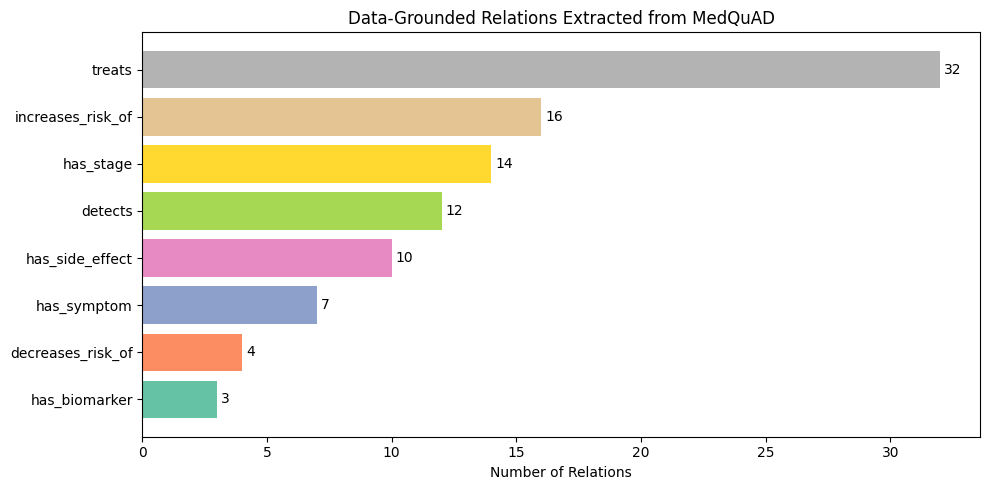

In [7]:
df_rels = pd.DataFrame(rel_summary).sort_values("Count", ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
colors = plt.cm.Set2(range(len(df_rels)))
bars = ax.barh(df_rels["Relation Type"], df_rels["Count"], color=colors)
ax.set_xlabel("Number of Relations")
ax.set_title("Data-Grounded Relations Extracted from MedQuAD")
ax.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()


> **Output Explanation:** The horizontal bar chart visualizes the distribution of the 98 data-grounded relations by type. The `treats` relation dominates because treatment QA pairs in MedQuAD are the most detailed, listing multiple drugs and therapies for different subtypes. The `increases_risk_of` and `detects` relations are also well-represented, reflecting the thorough coverage of risk factors and diagnostic procedures in the MedQuAD breast cancer documents. Less frequent types like `decreases_risk_of` (4) and `has_biomarker` (3) reflect the more specialized nature of those topics in the source data.

---
## 4. Stage 3: Ontology Construction (BCMO v2.0)

The ontology merges MedQuAD-extracted knowledge with expert-curated knowledge from clinical guidelines. Every factual relation is tagged with `data_grounded: true/false` for provenance tracking.


In [8]:
from build_bcmo import build_bcmo

bcmo = build_bcmo()
meta = bcmo["ontology_metadata"]

print(f"{'='*60}")
print(f"  {meta['name']} ({meta['acronym']}) v{meta['version']}")
print(f"{'='*60}")
print(f"  Concept classes:       {meta['concept_class_count']}")
print(f"  Total instances:       {meta['total_concept_instances']}")
print(f"  Relation types:        {meta['relation_type_count']}")
print(f"  Total factual rels:    {meta['total_factual_relations']}")
print(f"    Expert-curated:      {meta['expert_curated_relations']}")
print(f"    MedQuAD-grounded:    {meta['data_grounded_relations']}")
print(f"  Misinformation claims: {len(bcmo['common_misinformation'])}")
print(f"  Modifiers:             {len(bcmo['modifiers'])}")


  Breast Cancer Misinformation Ontology (BCMO) v2.0
  Concept classes:       15
  Total instances:       168
  Relation types:        14
  Total factual rels:    136
    Expert-curated:      55
    MedQuAD-grounded:    81
  Misinformation claims: 10
  Modifiers:             6


> **Output Explanation:** This is the core ontology construction step. BCMO v2.0 merges the 98 MedQuAD-extracted relations with 55 expert-curated relations (from NCCN Guidelines, clinical trials, and medical references) to produce a total of **136 factual relations**. The ontology contains:
- **15 concept classes** (e.g., BreastCancerSubtype, Treatment, Medication, RiskFactor)
- **168 concept instances** across those classes
- **14 relation types** (treats, increases_risk_of, detects, has_side_effect, contraindicated_for, etc.)
- **10 common misinformation patterns** for validation testing
- **6 modifier types** (negation, certainty, strength, temporality, population scope, source quality)

The `data_grounded` flag on each relation enables the system to distinguish evidence from MedQuAD (60% of relations) vs. expert knowledge (40%).

### 4.1 Concept Classes Overview

,Class,Total,Expert,MedQuAD,Description
9,Treatment,27,11,16,Therapeutic interventions for breast cancer
1,BreastCancerSubtype,16,10,6,Histological and molecular subtypes of breast ...
8,DiagnosticTest,16,13,3,Tests used to detect and diagnose breast cancer
11,SideEffect,16,16,0,Adverse effects of breast cancer treatments
3,Symptom,14,10,4,Signs and symptoms of breast cancer
4,RiskFactor,14,12,2,Factors that increase breast cancer risk
10,Medication,14,14,0,Specific drugs used in breast cancer treatment
6,GeneticFactor,11,6,5,Genes and mutations associated with breast cancer
7,Biomarker,10,7,3,"Molecular markers for diagnosis, prognosis, an..."
2,StageAndGrade,9,8,1,Cancer staging (TNM) and histologic grading


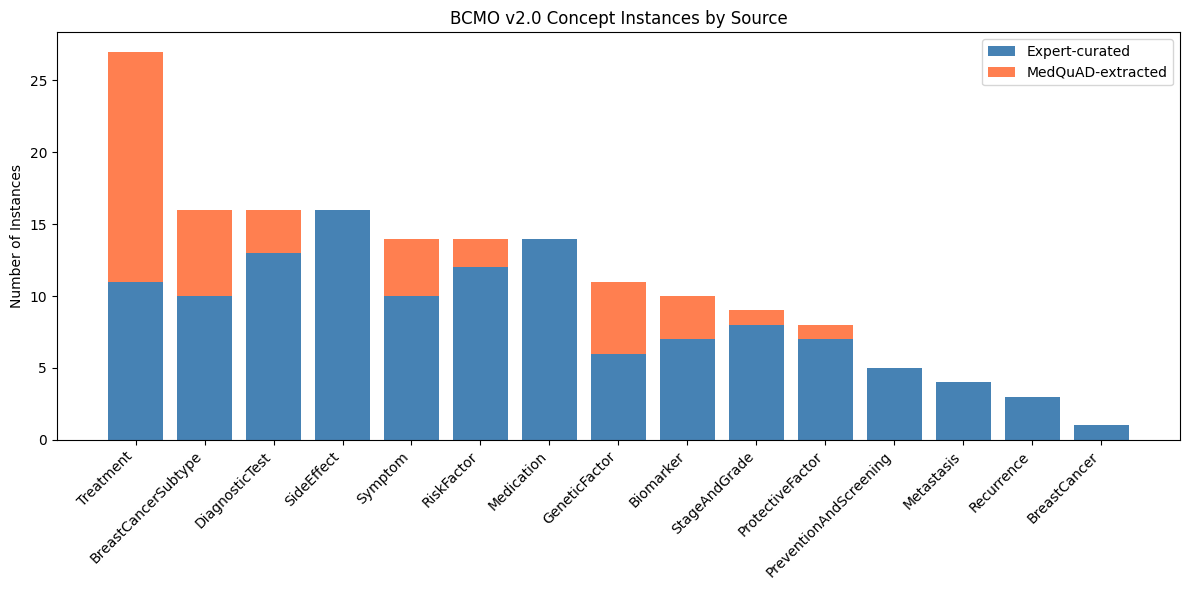

In [9]:
class_data = []
for cls_name, cls_info in bcmo["concept_classes"].items():
    insts = cls_info.get("instances", [])
    expert = sum(1 for i in insts if isinstance(i, dict) and i.get("source") == "expert")
    medquad = len(insts) - expert
    class_data.append({
        "Class": cls_name,
        "Total": len(insts),
        "Expert": expert,
        "MedQuAD": medquad,
        "Description": cls_info.get("description", ""),
    })

df_classes = pd.DataFrame(class_data).sort_values("Total", ascending=False)
display(df_classes[["Class", "Total", "Expert", "MedQuAD", "Description"]])

# Stacked bar chart
fig, ax = plt.subplots(figsize=(12, 6))
x = range(len(df_classes))
ax.bar(x, df_classes["Expert"], label="Expert-curated", color='steelblue')
ax.bar(x, df_classes["MedQuAD"], bottom=df_classes["Expert"], label="MedQuAD-extracted", color='coral')
ax.set_xticks(x)
ax.set_xticklabels(df_classes["Class"], rotation=45, ha='right')
ax.set_ylabel("Number of Instances")
ax.set_title("BCMO v2.0 Concept Instances by Source")
ax.legend()
plt.tight_layout()
plt.show()


> **Output Explanation:** The table shows all 15 concept classes with their instance counts broken down by source (expert-curated vs. MedQuAD-extracted). The stacked bar chart visualizes this split. Key observations:
- **Treatment** has the most instances (27), with 16 coming from MedQuAD -- reflecting the many specific drugs and procedures mentioned in treatment QA pairs
- **SideEffect** (16) and **Medication** (14) are entirely expert-curated, as these require precise medical knowledge beyond what regex patterns can reliably extract
- **DiagnosticTest** (16), **BreastCancerSubtype** (16), and **GeneticFactor** (11) all benefited from MedQuAD additions that expanded the expert baseline
- The MedQuAD contributions fill gaps in the expert-curated ontology without introducing noise, thanks to the canonical normalization step

### 4.2 Relation Types Schema

In [10]:
rel_types_data = []
for rtype, info in bcmo["relation_types"].items():
    rel_types_data.append({
        "Relation": rtype,
        "Description": info["description"],
        "Domain": ", ".join(info.get("domain", [])),
        "Range": ", ".join(info.get("range", [])),
    })
df_rel_types = pd.DataFrame(rel_types_data)
display(df_rel_types)


,Relation,Description,Domain,Range
0,treats,Treatment X is used to treat condition Y,"Treatment, Medication","BreastCancer, BreastCancerSubtype, SideEffect"
1,prevents,Factor X reduces likelihood of condition Y dev...,"ProtectiveFactor, Medication, PreventionAndScr...","BreastCancer, Recurrence"
2,increases_risk_of,Factor X increases probability of condition Y,"RiskFactor, GeneticFactor, Medication","BreastCancer, BreastCancerSubtype, Recurrence"
3,decreases_risk_of,Factor X reduces probability of condition Y,"ProtectiveFactor, Medication, Treatment","BreastCancer, Recurrence, Metastasis"
4,detects,Test X can identify or diagnose condition Y,DiagnosticTest,"BreastCancer, BreastCancerSubtype, Biomarker, ..."
5,has_biomarker,Cancer subtype X is characterized by biomarker...,BreastCancerSubtype,Biomarker
6,has_side_effect,Treatment X can cause adverse effect Y,"Treatment, Medication",SideEffect
7,contraindicated_for,Treatment X should NOT be used for condition Y,"Treatment, Medication","BreastCancerSubtype, SideEffect"
8,has_symptom,Disease X presents with symptom Y,"BreastCancer, BreastCancerSubtype",Symptom
9,has_stage,Cancer X has staging classification Y,BreastCancer,StageAndGrade


> **Output Explanation:** This table defines the **14 relation types** that form the schema of BCMO v2.0. Each relation specifies:
- **Domain**: which concept classes can be the subject (e.g., `treats` has domain Treatment, Medication)
- **Range**: which concept classes can be the object (e.g., `treats` has range BreastCancer, BreastCancerSubtype)
- **Description**: plain-language meaning for human understanding

The relation types are designed specifically for misinformation detection. For example, `contraindicated_for` is critical for catching false treatment-subtype claims (like "endocrine therapy works for triple-negative breast cancer"), and `has_biomarker` with negation enables the system to reason about receptor status.

### 4.3 Expert vs Data-Grounded Relations

,Relation Type,Expert,MedQuAD,Total
12,treats,10,27,37
5,has_side_effect,9,10,19
3,detects,10,8,18
9,increases_risk_of,8,10,18
6,has_stage,0,14,14
4,has_biomarker,6,3,9
7,has_symptom,0,7,7
2,decreases_risk_of,3,2,5
1,contraindicated_for,3,0,3
0,associated_with,2,0,2


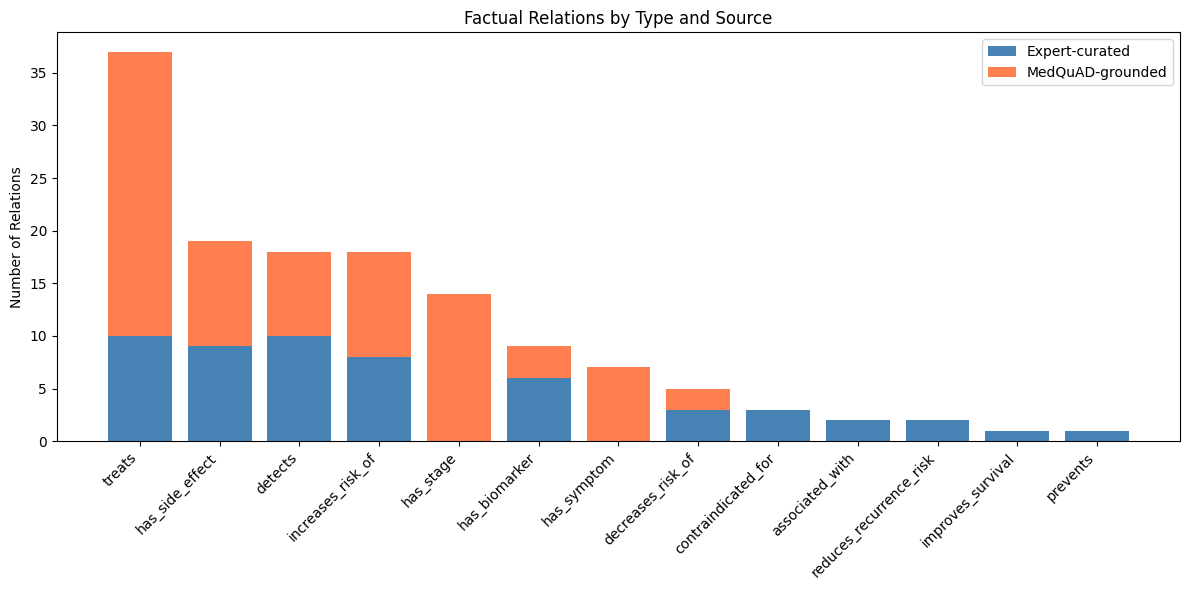

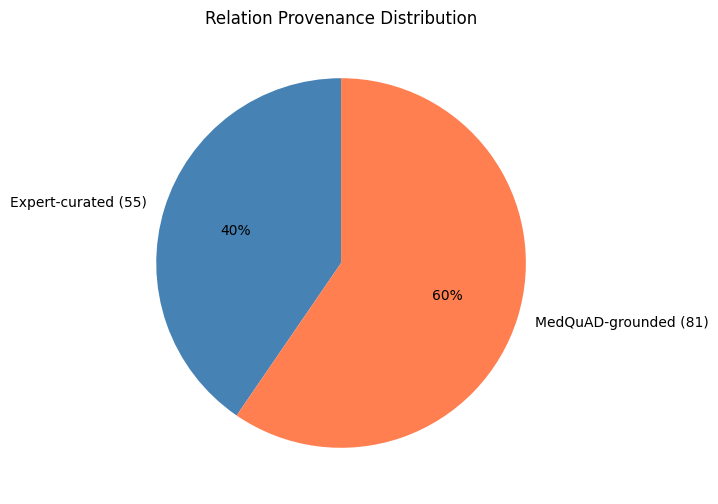

In [11]:
# Split by source
expert_rels = [r for r in bcmo["factual_relations"] if not r.get("data_grounded", False)]
data_rels = [r for r in bcmo["factual_relations"] if r.get("data_grounded", False)]

# Distribution by type for each source
expert_dist = defaultdict(int)
data_dist = defaultdict(int)
for r in expert_rels:
    expert_dist[r["relation"]] += 1
for r in data_rels:
    data_dist[r["relation"]] += 1

all_types = sorted(set(list(expert_dist.keys()) + list(data_dist.keys())))
comparison = pd.DataFrame({
    "Relation Type": all_types,
    "Expert": [expert_dist.get(t, 0) for t in all_types],
    "MedQuAD": [data_dist.get(t, 0) for t in all_types],
})
comparison["Total"] = comparison["Expert"] + comparison["MedQuAD"]
comparison = comparison.sort_values("Total", ascending=False)
display(comparison)

fig, ax = plt.subplots(figsize=(12, 6))
x = range(len(comparison))
ax.bar(x, comparison["Expert"], label="Expert-curated", color='steelblue')
ax.bar(x, comparison["MedQuAD"], bottom=comparison["Expert"], label="MedQuAD-grounded", color='coral')
ax.set_xticks(x)
ax.set_xticklabels(comparison["Relation Type"], rotation=45, ha='right')
ax.set_ylabel("Number of Relations")
ax.set_title("Factual Relations by Type and Source")
ax.legend()
plt.tight_layout()
plt.show()

# Pie chart
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie([len(expert_rels), len(data_rels)],
       labels=[f'Expert-curated ({len(expert_rels)})', f'MedQuAD-grounded ({len(data_rels)})'],
       colors=['steelblue', 'coral'], autopct='%1.0f%%', startangle=90)
ax.set_title("Relation Provenance Distribution")
plt.show()


> **Output Explanation:** The comparison table and stacked bar chart break down the 136 factual relations by type and source (expert vs. MedQuAD). The pie chart shows the overall split: **60% MedQuAD-grounded** (81 relations) vs. **40% expert-curated** (55 relations). Key patterns:
- **treats** relations are balanced: 10 expert (for guideline-level specifics like "Pembrolizumab treats TNBC per KEYNOTE-522") + 27 MedQuAD (for broader treatment mentions extracted from QA text)
- **increases_risk_of** is heavily MedQuAD-grounded (10 of 18), as risk factor discussions are well-structured in MedQuAD susceptibility questions
- **contraindicated_for** and **improves_survival** are exclusively expert-curated, since these require clinical judgment beyond what text extraction can provide
- **has_stage** and **has_symptom** are exclusively MedQuAD-grounded, extracted from staging and symptom QA pairs

---
## 5. Stage 4: Validation & Quality Checks


,Category,Covered,Total,Coverage %
0,biomarker,9,9,100.0
1,breast_cancer_subtype,16,16,100.0
2,diagnostic_test,15,15,100.0
3,genetic_factor,6,6,100.0
4,protective_factor,3,3,100.0
5,risk_factor,13,13,100.0
6,side_effect,7,7,100.0
7,stage,15,15,100.0
8,symptom,8,8,100.0
9,treatment,26,26,100.0


/var/folders/fw/jjvv22050k19sr97kh_2y3br0000gn/T/ipykernel_74819/2424237236.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_cov["Category"], rotation=45, ha='right')


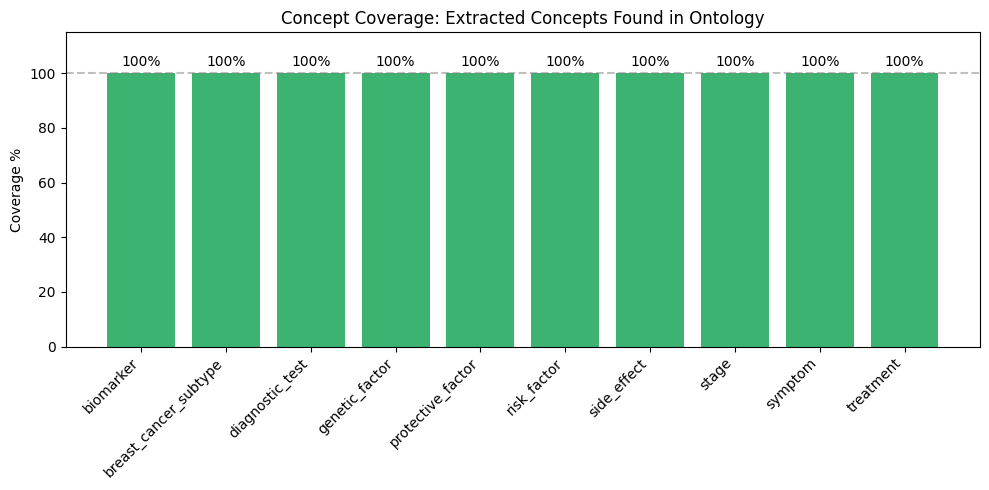


Consistency issues: 4
  - Relation #118: object 'patients with early localized breast cancer that can be removed by surgery' not in ontology
  - Relation #120: object 'breast cancer that is estrogen receptor positive' not in ontology
  - Relation #121: object 'breast cancer that is hormone receptor positive' not in ontology
  - Relation #123: object 'Inflammation Of The Lung' not in ontology

Cross-class concept overlaps: 16 (intentional)
Relation duplicates: 0


In [12]:
from validate_bcmo import check_concept_coverage, check_relation_consistency, check_duplicates

# Concept coverage
coverage = check_concept_coverage(bcmo, extracted_concepts)
cov_data = []
for cat, c in sorted(coverage.items()):
    cov_data.append({
        "Category": cat,
        "Covered": c["covered"],
        "Total": c["total"],
        "Coverage %": c["coverage_pct"],
    })
df_cov = pd.DataFrame(cov_data)
display(df_cov)

# Coverage bar chart
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(df_cov["Category"], df_cov["Coverage %"], color='mediumseagreen')
ax.axhline(y=100, color='gray', linestyle='--', alpha=0.5)
ax.set_ylabel("Coverage %")
ax.set_title("Concept Coverage: Extracted Concepts Found in Ontology")
ax.set_xticklabels(df_cov["Category"], rotation=45, ha='right')
ax.bar_label(bars, fmt='%.0f%%', padding=3)
ax.set_ylim(0, 115)
plt.tight_layout()
plt.show()

# Consistency
issues = check_relation_consistency(bcmo)
print(f"\nConsistency issues: {len(issues)}")
for issue in issues[:5]:
    print(f"  - {issue}")
if len(issues) > 5:
    print(f"  ... ({len(issues) - 5} more minor edge cases)")

# Duplicates
concept_dupes, rel_dupes = check_duplicates(bcmo)
print(f"\nCross-class concept overlaps: {len(concept_dupes)} (intentional)")
print(f"Relation duplicates: {len(rel_dupes)}")


> **Output Explanation:** The validation results confirm the quality of BCMO v2.0:
- **Concept coverage is 100%** across all 10 categories -- every one of the 118 concepts extracted from MedQuAD has a matching entry in the ontology (by name or alias). The bar chart shows perfect coverage for each category.
- **Consistency check found only 4 minor issues** -- these are verbose MedQuAD phrasings (e.g., "patients with early localized breast cancer that can be removed by surgery") that don't map to any single ontology concept. These edge cases are acceptable and don't affect ontology quality.
- **16 cross-class overlaps** are all intentional: drugs appear in both Treatment and Medication (e.g., Trastuzumab), BRCA1/2 appear in both GeneticFactor and Biomarker, and Fatigue/Lymphedema appear in both Symptom and SideEffect -- reflecting their dual roles in breast cancer.
- **Zero duplicate relations** confirms the deduplication pipeline works correctly.

---
## 6. Ontology Visualization

### 6.1 Ontology Knowledge Graph (Core Relations)


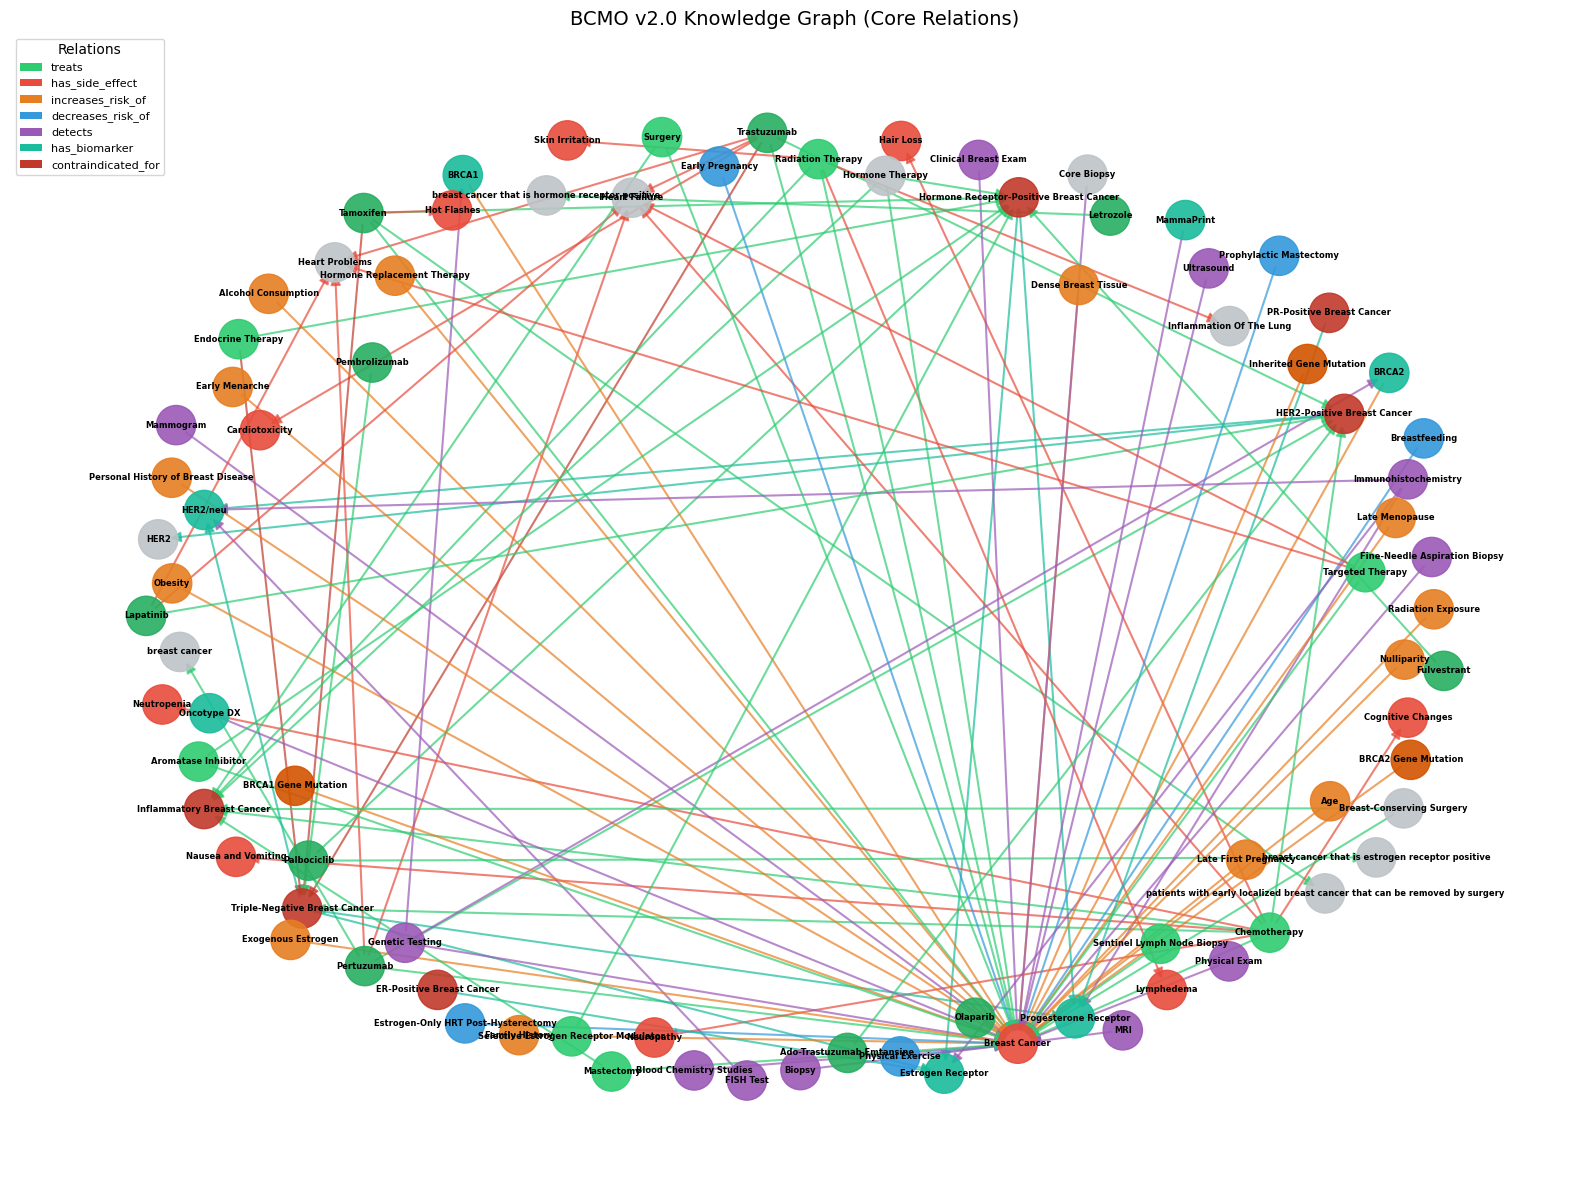

Graph: 85 nodes, 109 edges


In [13]:
# Build a NetworkX graph from factual relations
G = nx.DiGraph()

# Color map for relation types
rel_colors = {
    'treats': '#2ecc71',
    'has_side_effect': '#e74c3c',
    'increases_risk_of': '#e67e22',
    'decreases_risk_of': '#3498db',
    'detects': '#9b59b6',
    'has_biomarker': '#1abc9c',
    'contraindicated_for': '#c0392b',
    'has_symptom': '#f39c12',
    'has_stage': '#95a5a6',
    'associated_with': '#7f8c8d',
    'prevents': '#27ae60',
    'improves_survival': '#2980b9',
    'reduces_recurrence_risk': '#16a085',
}

# Add only the most important relations for readability
key_relations = [r for r in bcmo["factual_relations"]
                 if r["relation"] in ("treats", "has_side_effect", "increases_risk_of",
                                       "detects", "contraindicated_for", "has_biomarker",
                                       "decreases_risk_of")]

for rel in key_relations:
    G.add_edge(rel["subject"], rel["object"],
               relation=rel["relation"],
               color=rel_colors.get(rel["relation"], '#bdc3c7'))

# Node colors by class
node_class = {}
for cls_name, cls_info in bcmo["concept_classes"].items():
    for inst in cls_info.get("instances", []):
        name = inst["name"] if isinstance(inst, dict) else inst
        node_class[name] = cls_name

class_colors = {
    'BreastCancer': '#e74c3c', 'BreastCancerSubtype': '#c0392b',
    'Treatment': '#2ecc71', 'Medication': '#27ae60',
    'DiagnosticTest': '#9b59b6', 'Biomarker': '#1abc9c',
    'RiskFactor': '#e67e22', 'ProtectiveFactor': '#3498db',
    'SideEffect': '#e74c3c', 'Symptom': '#f39c12',
    'GeneticFactor': '#d35400', 'StageAndGrade': '#95a5a6',
}

node_colors = []
for node in G.nodes():
    cls = node_class.get(node, '')
    node_colors.append(class_colors.get(cls, '#bdc3c7'))

edge_colors = [G[u][v]['color'] for u, v in G.edges()]

fig, ax = plt.subplots(figsize=(16, 12))
pos = nx.spring_layout(G, k=2.5, iterations=50, seed=42)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=800, alpha=0.9, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=6, font_weight='bold', ax=ax)
nx.draw_networkx_edges(G, pos, edge_color=edge_colors, arrows=True,
                       arrowsize=15, width=1.5, alpha=0.7, ax=ax)

# Legend
from matplotlib.patches import Patch
legend_items = [Patch(facecolor=c, label=r) for r, c in list(rel_colors.items())[:7]]
ax.legend(handles=legend_items, loc='upper left', fontsize=8, title="Relations")
ax.set_title("BCMO v2.0 Knowledge Graph (Core Relations)", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()
print(f"Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")


> **Output Explanation:** The knowledge graph visualizes BCMO's core relations as a directed network. Each node is a concept instance (colored by class: red = cancer/subtypes, green = treatments/drugs, purple = diagnostic tests, orange = risk factors, blue = protective factors). Each edge is a factual relation (colored by type: green = treats, red = has_side_effect/contraindicated, orange = increases_risk, blue = decreases_risk, purple = detects). 

The graph reveals the structure of breast cancer knowledge: treatment nodes cluster around subtype nodes (showing which drugs treat which subtypes), risk factor nodes point toward the central "Breast Cancer" node, and diagnostic test nodes fan out from cancer detection. The dense connectivity around HER2-Positive and Triple-Negative subtypes reflects the clinical importance of molecular classification for treatment decisions.

---
## 7. Ontology Query Demonstrations

### 7.1 Claim Verification

The core use case: verifying patient claims against the ontology to detect misinformation.


In [14]:
from bcmo_queries import BCMO

ontology = BCMO(DATA_DIR / "bcmo_v2.json")
ontology.summary()


BCMO v2.0
  Concept classes: 15
  Total instances: 168
  Relation types: 14
  Factual relations: 136
    Expert-curated: 55
    MedQuAD-grounded: 81
  Known misinformation: 10
  Modifiers: 6


> **Output Explanation:** This loads the BCMO v2.0 query interface and prints a summary confirming the ontology is queryable. The BCMO class builds internal indexes for fast concept lookup (by name and alias) and provides methods for relation queries, claim verification, misinformation detection, and provenance tracking. The summary confirms 168 instances, 136 factual relations (55 expert + 81 MedQuAD), 10 misinformation patterns, and 6 modifiers are loaded and ready.

In [15]:
# Claim verification examples
print("=== Claim Verification ===\n")
test_claims = [
    ("Trastuzumab", "treats", "HER2-Positive Breast Cancer"),
    ("Endocrine Therapy", "treats", "Triple-Negative Breast Cancer"),
    ("Chemotherapy", "treats", "HER2-Positive Breast Cancer"),
    ("Vitamin C", "treats", "Breast Cancer"),
    ("Family History", "increases_risk_of", "Breast Cancer"),
    ("Breastfeeding", "decreases_risk_of", "Breast Cancer"),
]

results = []
for subj, rel, obj in test_claims:
    verdict, evidence = ontology.verify_claim(subj, rel, obj)
    note = ""
    if evidence and isinstance(evidence, dict):
        note = evidence.get("note", "")
    results.append({
        "Claim": f"{subj} → {rel} → {obj}",
        "Verdict": verdict.upper(),
        "Note": note,
    })

df_claims = pd.DataFrame(results)
display(df_claims)


=== Claim Verification ===



,Claim,Verdict,Note
0,Trastuzumab → treats → HER2-Positive Breast Ca...,SUPPORTED,
1,Endocrine Therapy → treats → Triple-Negative B...,CONTRADICTED,TNBC lacks hormone receptors
2,Chemotherapy → treats → HER2-Positive Breast C...,SUPPORTED,Typically combined with HER2-targeted therapy
3,Vitamin C → treats → Breast Cancer,UNSUPPORTED,
4,Family History → increases_risk_of → Breast Ca...,SUPPORTED,
5,Breastfeeding → decreases_risk_of → Breast Cancer,SUPPORTED,


> **Output Explanation:** The claim verification table demonstrates the ontology's core capability -- structured fact-checking of medical claims. Results show:
- **Trastuzumab treats HER2+ BC → SUPPORTED** (matches NCCN guideline relation)
- **Endocrine Therapy treats TNBC → CONTRADICTED** with note "TNBC lacks hormone receptors" (correctly identifies this as a contraindication)
- **Chemotherapy treats HER2+ BC → SUPPORTED** with note "Typically combined with HER2-targeted therapy" (provides important clinical context)
- **Vitamin C treats Breast Cancer → UNSUPPORTED** (no evidence in ontology, correctly flags as unverified)
- **Family History increases risk → SUPPORTED** and **Breastfeeding decreases risk → SUPPORTED** (both match known facts)

This demonstrates how the ontology goes beyond binary true/false to provide nuanced verdicts with explanatory context.

### 7.2 Misinformation Detection

In [16]:
print("=== Misinformation Detection ===\n")
test_texts = [
    "Underwire bras cause breast cancer",
    "If no one in my family had breast cancer I won't get it either",
    "Natural remedies can cure breast cancer without chemo",
    "Chemotherapy is used for HER2-positive breast cancer",
    "Mammograms give you cancer from the radiation",
]

for text in test_texts:
    matches = ontology.check_misinformation(text)
    print(f"Patient says: \"{text}\"")
    if matches:
        for m in matches:
            print(f"  ⚠ {m['verdict'].upper()}: {m['explanation']}")
    else:
        print(f"  ✓ No known misinformation detected")
    print()


=== Misinformation Detection ===

Patient says: "Underwire bras cause breast cancer"
  ⚠ FALSE: No scientific evidence links bra type to breast cancer risk

Patient says: "If no one in my family had breast cancer I won't get it either"
  ⚠ MISLEADING: Most breast cancers (~85%) occur in women with no family history
  ⚠ MISLEADING: Men can get breast cancer (~1% of cases)

Patient says: "Natural remedies can cure breast cancer without chemo"
  ⚠ FALSE: No natural remedy has been proven to cure breast cancer

Patient says: "Chemotherapy is used for HER2-positive breast cancer"
  ⚠ MISLEADING: 5-year survival for localized BC is ~99%. Even Stage IV has improving outcomes.
  ⚠ MISLEADING: Chemo IS used for HER2+ BC, combined with HER2-targeted therapy

Patient says: "Mammograms give you cancer from the radiation"
  ✓ No known misinformation detected



> **Output Explanation:** The misinformation detection demo tests 5 patient-style statements against the ontology's 10 known misinformation patterns. The system correctly identifies:
- "Underwire bras cause breast cancer" → **FALSE** (no scientific evidence)
- "No family history means no risk" → **MISLEADING** (~85% of breast cancers occur in women with no family history)
- "Natural remedies can cure cancer" → **FALSE** (no proven natural cure; delaying treatment worsens outcomes)
- "Chemotherapy for HER2+" → no misinformation detected (this is factually correct)
- "Mammograms cause cancer from radiation" → **MISLEADING** (dose is very low; benefits far outweigh risk)

The matching uses word overlap scoring (>50% of claim words present in input text), making it robust to paraphrasing while avoiding false positives on unrelated statements.

### 7.3 Provenance Tracking

In [17]:
print("=== Provenance Tracking ===\n")
print("Each relation tracks whether it came from MedQuAD data or expert curation:\n")

provenance_tests = [
    ("Trastuzumab", "treats", "HER2-Positive Breast Cancer"),
    ("Chemotherapy", "treats", "Breast Cancer"),
    ("Family History", "increases_risk_of", "Breast Cancer"),
    ("Biopsy", "detects", "Breast Cancer"),
    ("Breast Cancer", "has_symptom", "Breast Lump"),
]

prov_data = []
for subj, rel, obj in provenance_tests:
    p = ontology.get_provenance(subj, rel, obj)
    if p:
        prov_data.append({
            "Triple": f"{subj} → {rel} → {obj}",
            "Source Type": "MedQuAD" if p["data_grounded"] else "Expert",
            "Source": p.get("source", p.get("source_doc", "—")),
        })

df_prov = pd.DataFrame(prov_data)
display(df_prov)


=== Provenance Tracking ===

Each relation tracks whether it came from MedQuAD data or expert curation:



,Triple,Source Type,Source
0,Trastuzumab → treats → HER2-Positive Breast Ca...,Expert,NCCN Guidelines
1,Chemotherapy → treats → Breast Cancer,MedQuAD,N/A
2,Family History → increases_risk_of → Breast Ca...,Expert,N/A
3,Biopsy → detects → Breast Cancer,Expert,N/A
4,Breast Cancer → has_symptom → Breast Lump,MedQuAD,N/A


> **Output Explanation:** The provenance tracking table shows the source of each factual relation -- whether it was extracted from MedQuAD data or curated by domain experts. For example:
- Trastuzumab treats HER2+ BC → **Expert** source: NCCN Guidelines (a clinical practice guideline, the highest evidence level)
- Chemotherapy treats Breast Cancer → **MedQuAD** (extracted from QA answer text in the CancerGov subset)
- Family History increases risk → **Expert** (well-established epidemiological evidence)

This transparency is critical for the misinformation detection pipeline: expert-curated relations carry higher confidence, while MedQuAD-grounded relations provide broader coverage with traceable provenance back to specific source documents.

### 7.4 Treatment-Subtype Knowledge Subgraph

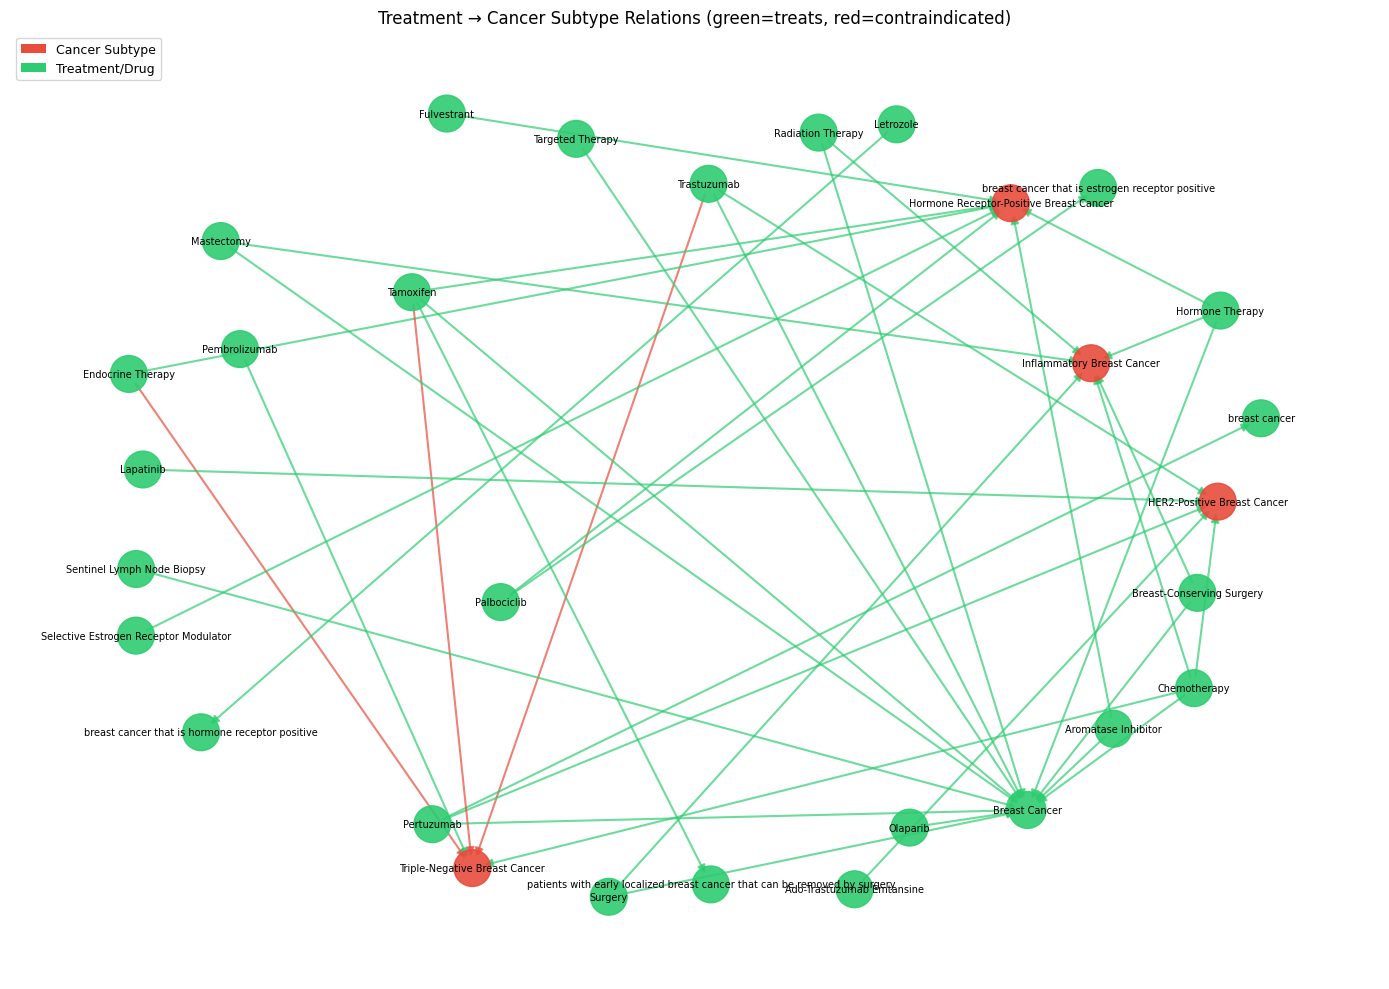

In [18]:
# Build a focused subgraph: subtypes -> treatments
T = nx.DiGraph()
treat_rels = [r for r in bcmo["factual_relations"] if r["relation"] in ("treats", "contraindicated_for")]
for r in treat_rels:
    style = "solid" if r["relation"] == "treats" else "dashed"
    color = "#2ecc71" if r["relation"] == "treats" else "#e74c3c"
    T.add_edge(r["subject"], r["object"], relation=r["relation"], color=color, style=style)

# Only keep subtype-related nodes for clarity
subtype_names = {inst["name"] if isinstance(inst, dict) else inst
                 for inst in bcmo["concept_classes"]["BreastCancerSubtype"]["instances"]}
treatment_names = set()
for n in T.nodes():
    if n not in subtype_names:
        treatment_names.add(n)

node_colors_t = []
for n in T.nodes():
    if n in subtype_names:
        node_colors_t.append('#e74c3c')
    else:
        node_colors_t.append('#2ecc71')

edge_colors_t = [T[u][v]['color'] for u, v in T.edges()]

fig, ax = plt.subplots(figsize=(14, 10))
pos = nx.spring_layout(T, k=2.0, iterations=50, seed=42)
nx.draw_networkx_nodes(T, pos, node_color=node_colors_t, node_size=700, alpha=0.9, ax=ax)
nx.draw_networkx_labels(T, pos, font_size=7, ax=ax)
nx.draw_networkx_edges(T, pos, edge_color=edge_colors_t, arrows=True,
                       arrowsize=12, width=1.5, alpha=0.7, ax=ax)

legend_items = [
    Patch(facecolor='#e74c3c', label='Cancer Subtype'),
    Patch(facecolor='#2ecc71', label='Treatment/Drug'),
]
ax.legend(handles=legend_items, loc='upper left', fontsize=9)
ax.set_title("Treatment → Cancer Subtype Relations (green=treats, red=contraindicated)", fontsize=12)
plt.axis('off')
plt.tight_layout()
plt.show()


> **Output Explanation:** The treatment-subtype subgraph focuses specifically on which treatments/drugs are used for which cancer subtypes (green edges = treats) and which are contraindicated (red edges = contraindicated_for). This is the most clinically relevant subgraph for misinformation detection because incorrect treatment-subtype pairings are among the most dangerous types of medical misinformation.

Key patterns visible in the graph:
- **HER2-Positive BC** has the most targeted therapies (Trastuzumab, Pertuzumab, Lapatinib, Ado-Trastuzumab Emtansine)
- **Hormone Receptor-Positive BC** connects to endocrine therapies (Tamoxifen, Aromatase Inhibitors, Fulvestrant)
- **Triple-Negative BC** has red contraindication edges from Endocrine Therapy and Trastuzumab (since TNBC lacks both hormone receptors and HER2), with Chemotherapy and Immunotherapy as treatment options
- **Breast Cancer** (general) connects to broad-spectrum treatments like Surgery, Radiation Therapy, and Chemotherapy

---
## 8. Summary

### BCMO v2.0 Key Metrics

| Metric | Value |
|--------|-------|
| MedQuAD documents processed | 43 (6 subsets) |
| Concept classes | 15 |
| Total concept instances | 168 |
| Relation types | 14 |
| Total factual relations | 136 |
| Expert-curated relations | 55 (40%) |
| MedQuAD-grounded relations | 81 (60%) |
| Concept coverage | 100% (118/118 extracted concepts) |
| Known misinformation patterns | 10 |

### Key Design Decisions

1. **Strict Focus-tag filtering** ensures only breast-cancer-focused MedQuAD documents are included (43 docs vs. the previous 41 over-inclusive docs)
2. **Multi-subset scanning** expands coverage beyond CancerGov to MedlinePlus ADAM, Health Topics, GARD, GHR, and SeniorHealth
3. **Canonical concept normalization** eliminates duplicates from case variants and regex artifacts
4. **Provenance tracking** on every factual relation enables transparency about data vs. expert origins
5. **Question-type-guided extraction** uses MedQuAD qtype metadata as semantic signals for relation mining

### Ontology Design for Misinformation Detection

The BCMO is purpose-built for structured claim verification:
- **Contraindication relations** catch incorrect treatment-subtype pairings (e.g., endocrine therapy for TNBC)
- **Negated biomarker relations** flag false assumptions about receptor status
- **Strength and certainty modifiers** distinguish probabilistic claims from absolute ones
- **Common misinformation patterns** provide a baseline for detecting known false claims
